In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

       Probe_ID   GSM820516   GSM820517   GSM820518   GSM820519   GSM820520  \
0  ILMN_1343291  66665.3800  69404.6700  64128.0700  68943.9700  67827.2200   
1  ILMN_1343295  22040.1100  13046.3400  38678.9600  16641.8900  33719.8900   
2  ILMN_1651199    226.6081    205.4483    217.2475    229.0451    226.3029   
3  ILMN_1651209    278.5710    253.7044    211.8002    278.0423    259.8059   
4  ILMN_1651210    195.4914    195.9835    175.3356    193.9065    229.5674   

    GSM820521   GSM820522   GSM820523   GSM820524   GSM820525   GSM820526  \
0  71775.3000  62245.5900  69713.7000  69509.2700  68244.5900  65427.4700   
1  18933.2900  26170.0400   9906.9130  17166.5200  12428.9500  25297.5700   
2    203.8710    213.4431    210.4129    229.5394    212.7384    226.1345   
3    265.1900    321.2587    273.4458    253.6032    310.1582    275.0126   
4    164.0632    244.6696    190.9813    188.1039    199.3084    220.6229   

    GSM820527   GSM820528   GSM820529   GSM820530   GSM820531 

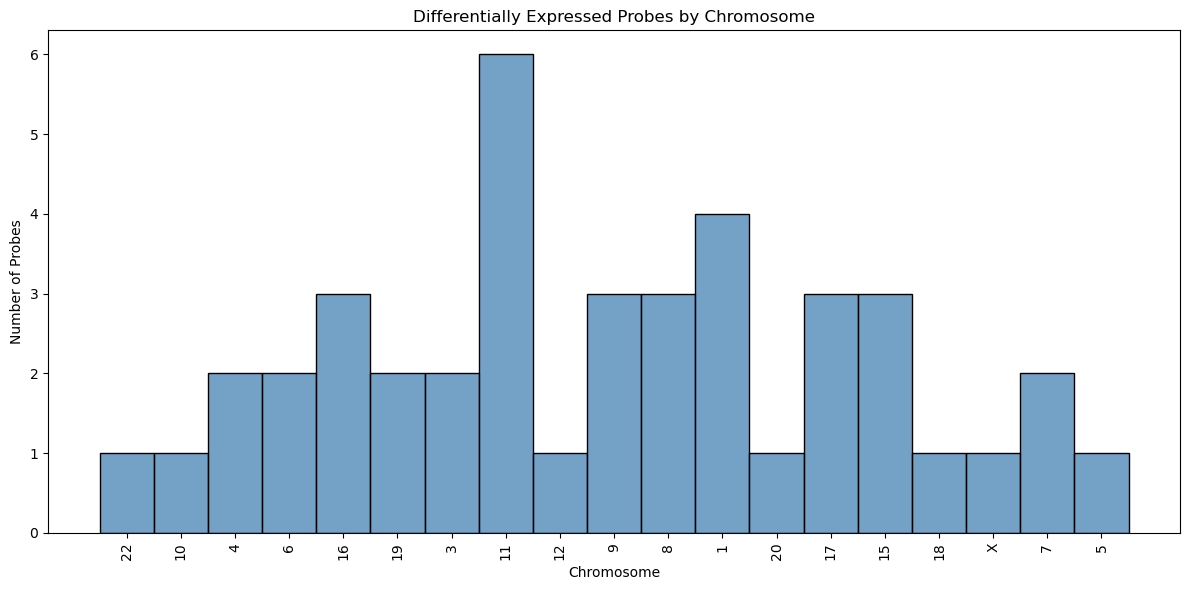

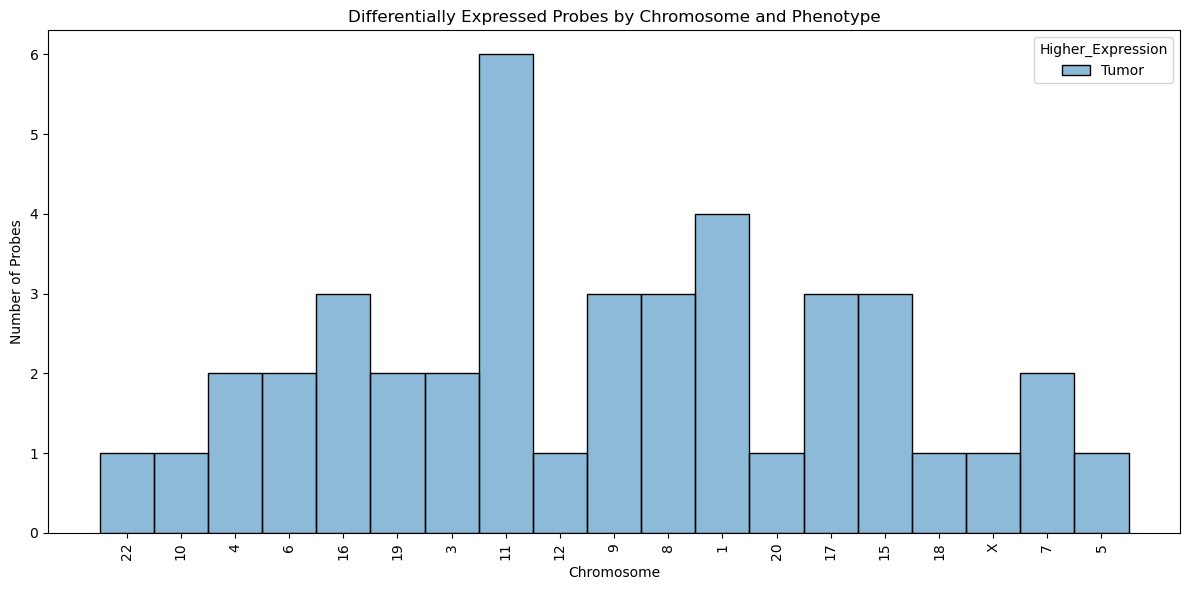

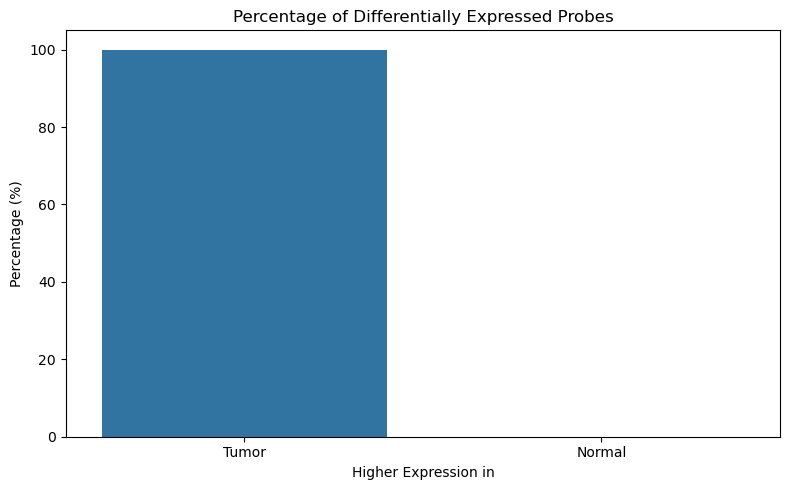

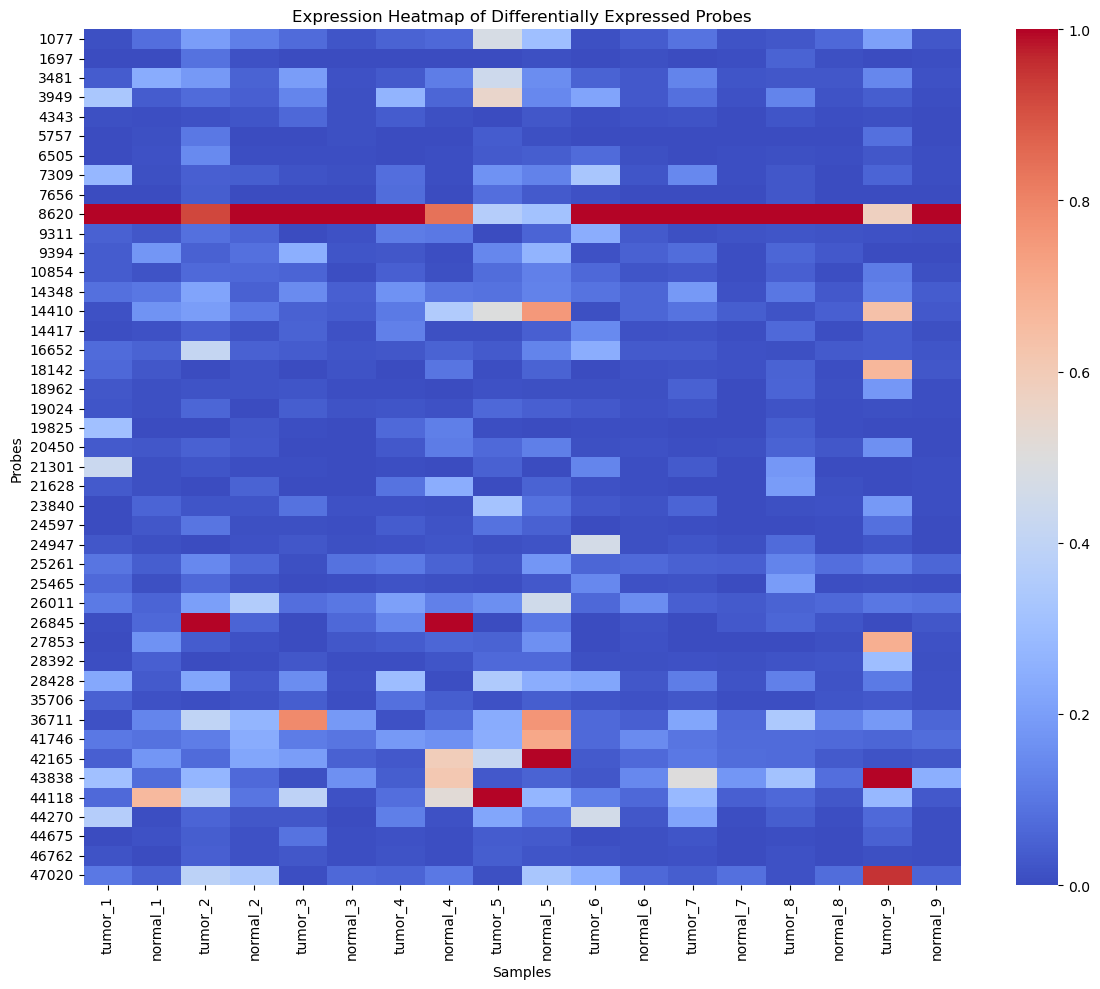

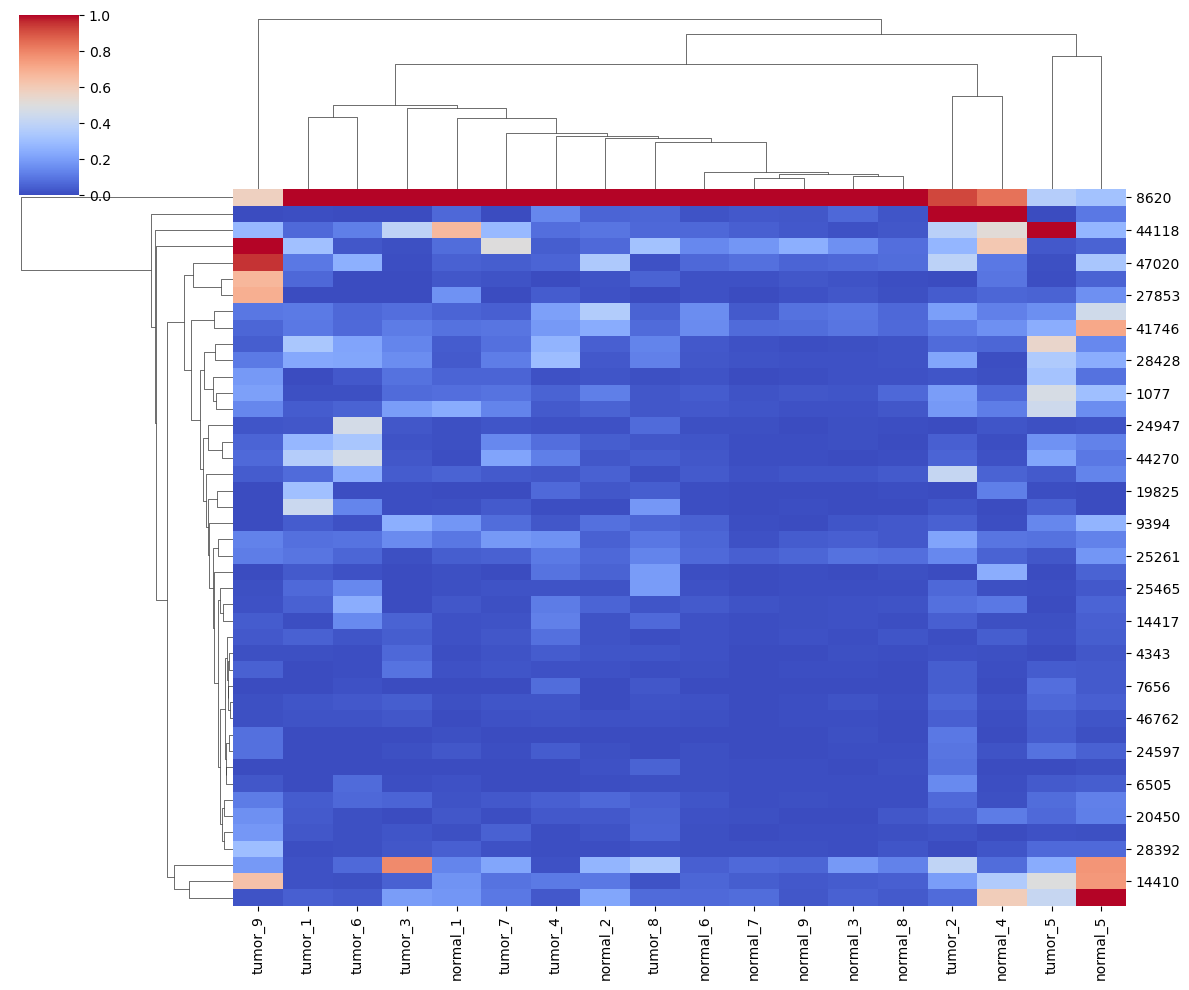

Total probes:
48803
Probes after merging:
48803
Differentially expressed probes:
44
Higher expression by phenotype:
Higher_Expression
Tumor    44
Name: count, dtype: int64
Tumor percentage:
100.0
Normal percentage:
0.0


In [19]:
gene_expression = pd.read_excel("Gene_Expression_Data.xlsx")
gene_information = pd.read_csv("Gene_Information.csv")
sample_information = pd.read_csv("Sample_Information.tsv", sep="\t")

# print the first 5 rows
print(gene_expression.head())
print(gene_information.head())
print(sample_information.head())

gene_expression.rename(
    columns = { 
        "GSM820516" : "tumor_1" ,
        "GSM820517" : "normal_1" , 
        "GSM820518" : "tumor_2" , 
        "GSM820519" : "normal_2" ,
        "GSM820520" : "tumor_3" ,
        "GSM820521" : "normal_3" ,
        "GSM820522" : "tumor_4" ,
        "GSM820523" : "normal_4" ,
        "GSM820524" : "tumor_5" ,
        "GSM820525" : "normal_5" ,
        "GSM820526" : "tumor_6" ,
        "GSM820527" : "normal_6" ,
        "GSM820528" : "tumor_7" ,
        "GSM820529" : "normal_7" ,
        "GSM820530" : "tumor_8" ,
        "GSM820531" : "normal_8" ,
        "GSM820532" : "tumor_9" ,
        "GSM820533" : "normal_9"
    },
    inplace = True
)
print(gene_expression.columns)  

tumor_data = gene_expression.filter([
    'Probe_ID' ,
    'tumor_1', 'tumor_2', 'tumor_3', 
    'tumor_4', 'tumor_5', 'tumor_6'
    'tumor_7', 'tumor_8', 'tumor_9'
])

normal_data = gene_expression.filter([
    'Probe_ID', 
    'normal_1', 'normal_2', 'normal_3'
    'normal_4', 'normal_5', 'normal_6'
    'normal_7', 'normal_8', 'normal_9'
])

print(normal_data.head())
print(tumor_data.head())


# Calculate the average expression for each probe

tumor_data['Tumor_Mean'] = tumor_data.filter([
    'tumor_1', 'tumor_2', 'tumor_3',
    'tumor_4', 'tumor_5', 'tumor_6',
    'tumor_7', 'tumor_8', 'tumor_9'
]).mean(axis = 1)

normal_data['Normal_Mean'] = normal_data.filter([
    'normal_1', 'normal_2', 'normal_3',
    'normal_4', 'normal_5', 'normal_6',
    'normal_7', 'normal_8', 'normal_9'
]).mean(axis = 1)

print(tumor_data.head())
print(normal_data.head())


# Combine the Tumor and Normal averages

tumor_average = tumor_data.filter(['Probe_ID', 'Tumor_Mean'])
normal_average = normal_data.filter(['Probe_ID', 'Normal_Mean'])

fold_change_data = pd.merge(
    tumor_average,
    normal_average,
    on = 'Probe_ID',
    how = 'inner'
)


# Calculate fold change for each probe

fold_change_data['Fold_Change'] = (
    (fold_change_data['Tumor_Mean'] - fold_change_data['Normal_Mean'])
    / fold_change_data['Normal_Mean']
)

print(fold_change_data.head())


# Combine fold change results with gene information

gene_results = pd.merge(
    fold_change_data,
    gene_information,
    on = 'Probe_ID',
    how = 'inner'
)


# Find probes with absolute fold change greater than 5

gene_results['Absolute_Fold_Change'] = abs(
    gene_results['Fold_Change']
)

deg_genes = gene_results.loc[
    gene_results['Absolute_Fold_Change'] > 5
].copy()

print(deg_genes.head())
print(len(deg_genes))


# Identify whether expression is higher in Tumor or Normal

deg_genes['Higher_Expression'] = np.where(
    deg_genes['Fold_Change'] > 0,
    'Tumor',
    'Normal'
)

print(deg_genes['Higher_Expression'].value_counts())


# Plot differentially expressed probes by chromosome

plt.figure(figsize = (12, 6))

sns.histplot(
    x = 'Chromosome',
    data = deg_genes,
    color = 'steelblue'
)

plt.title('Differentially Expressed Probes by Chromosome')
plt.xlabel('Chromosome')
plt.ylabel('Number of Probes')
plt.xticks(rotation = 90)
plt.tight_layout()
plt.savefig('Chromosome_Histogram.png')
plt.show()


# Plot chromosome distribution separated by phenotype

plt.figure(figsize = (12, 6))

sns.histplot(
    x = 'Chromosome',
    hue = 'Higher_Expression',
    data = deg_genes
)

plt.title('Differentially Expressed Probes by Chromosome and Phenotype')
plt.xlabel('Chromosome')
plt.ylabel('Number of Probes')
plt.xticks(rotation = 90)
plt.tight_layout()
plt.savefig('Phenotype_Histogram.png')
plt.show()


# Calculate percentage of probes higher in each phenotype

tumor_percent = (
    (deg_genes['Higher_Expression'] == 'Tumor').sum()
    / len(deg_genes)
) * 100

normal_percent = (
    (deg_genes['Higher_Expression'] == 'Normal').sum()
    / len(deg_genes)
) * 100

percent_data = pd.DataFrame({
    'Phenotype': ['Tumor', 'Normal'],
    'Percentage': [tumor_percent, normal_percent]
})


# Plot the percentages for Tumor and Normal

plt.figure(figsize = (8, 5))

sns.barplot(
    x = 'Phenotype',
    y = 'Percentage',
    data = percent_data
)

plt.title('Percentage of Differentially Expressed Probes')
plt.xlabel('Higher Expression in')
plt.ylabel('Percentage (%)')
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig('Expression_Percentage.png')
plt.show()


# Select original expression values for the qualifying probes

heatmap_data = gene_expression.loc[
    gene_expression['Probe_ID'].isin(deg_genes['Probe_ID'])
].copy()

heatmap_data = heatmap_data.drop(
    labels = ['Probe_ID'],
    axis = 1
)


# Normalize the expression values

heatmap_data = (
    (heatmap_data - heatmap_data.min())
    / (heatmap_data.max() - heatmap_data.min())
)


# Create a heatmap of the expression values

plt.figure(figsize = (12, 10))

sns.heatmap(
    heatmap_data,
    cmap = 'coolwarm'
)

plt.title('Expression Heatmap of Differentially Expressed Probes')
plt.xlabel('Samples')
plt.ylabel('Probes')
plt.tight_layout()
plt.savefig('Expression_Heatmap.png')
plt.show()


# Create a clustermap to group similar expression patterns

sns.clustermap(
    heatmap_data,
    cmap = 'coolwarm',
    figsize = (12, 10)
)

plt.savefig('Expression_Clustermap.png')
plt.show()


# Display the final analysis results

print('Total probes:')
print(len(gene_expression))

print('Probes after merging:')
print(len(gene_results))

print('Differentially expressed probes:')
print(len(deg_genes))

print('Higher expression by phenotype:')
print(deg_genes['Higher_Expression'].value_counts())

print('Tumor percentage:')
print(tumor_percent)

print('Normal percentage:')
print(normal_percent)


